Name Muhtasim Haque Nahian

Labpartner(s) Taherunnesa Rahi

In [4]:
#import statements go here
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator, PercentFormatter, MaxNLocator

# Class 8.2

Today we are having a guest lecture online by [Will Faulkner](https://www.linkedin.com/in/wnfaulkner/) on "vibe coding" aka the use of LLMs to build code when you have no or little idea what you are doing. 

**W.1** This week our warmups are focused on applying your Pandas skills. Please continue your analysis of the 2026 World Cup player stats from slack (pinned to #announcements). Make sure you write some text about what you found. 

In [2]:
# Load data

players = pd.read_csv("player_stats.csv")
display(players.head())

,player_id,player_name,team_id,position,matches_played,matches_started,minutes_played,goals,assists,shots,...,yellow_cards,red_cards,penalty_goals,own_goals,clean_sheets,saves,goals_conceded,average_rating,data_source,last_verified
0,1,José Raúl Rangel,1,GK,5,5,438,0,0,NaN,...,0,0,0,0,4.0,7.0,3.0,NaN,sofascore.com,2026-07-19
1,2,Jorge Eduardo Sanchez,1,DEF,5,5,439,0,1,NaN,...,0,0,0,0,NaN,NaN,NaN,NaN,sofascore.com,2026-07-19
2,3,César Jasib Montes,1,DEF,3,2,165,0,0,NaN,...,0,1,0,0,NaN,NaN,NaN,NaN,sofascore.com,2026-07-19
3,4,Edson Omar Alvarez,1,DEF,2,0,75,0,0,NaN,...,1,0,0,0,NaN,NaN,NaN,NaN,sofascore.com,2026-07-19
4,5,Johan Felipe Vasquez,1,DEF,2,2,180,0,0,NaN,...,0,0,0,0,NaN,NaN,NaN,NaN,sofascore.com,2026-07-19


### Comparison of Total and Per-90 Goal Contributions

I compared midfielders and forwards who played at least **450 minutes**, selecting the top 12 by goal contributions per 90 minutes. Goal contributions include both goals and assists:

$$
\text{Goal contributions} = \text{Goals} + \text{Assists}
$$

$$
\text{Goal contributions per 90}
= \frac{\text{Goals} + \text{Assists}}{\text{Minutes played}}\times90
$$

Then, I filtered eligible players, calculated these statistics, and ranked them by their per-90 contributions. In the stacked bar charts, the left panel shows total contributions, while the right panel shows contributions adjusted for playing time. Green represents goals, and blue represents assists.

The dashed line represents the **minutes-weighted benchmark** across all eligible players, calculated as:

$$
\text{Benchmark}
= \frac{\sum_i(\text{Goals}_i+\text{Assists}_i)}
{\sum_i\text{Minutes played}_i}\times90
$$

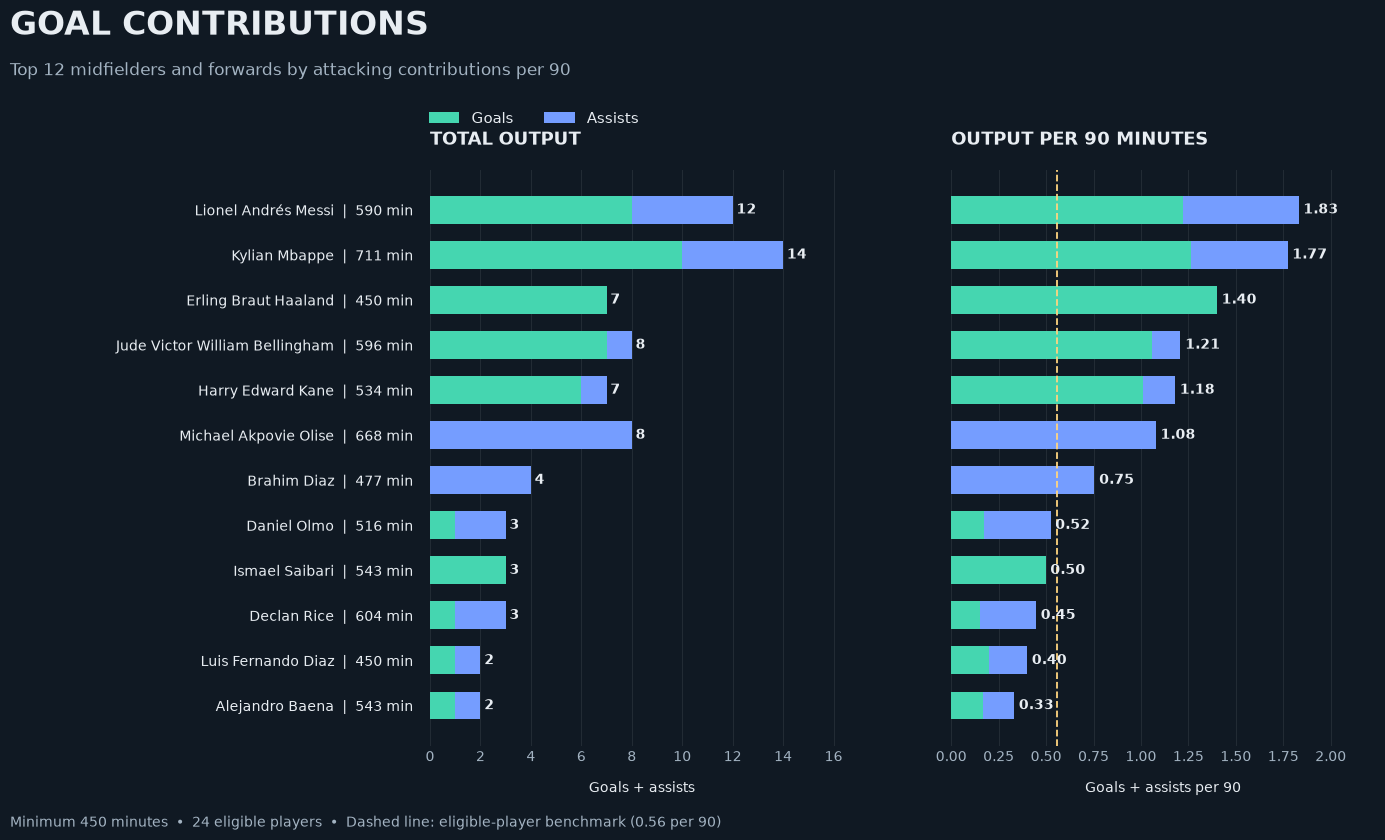

In [5]:
# Select attacking players with substantial playing time
attackers = players.loc[players["position"].isin(["FWD", "MID"]) &
    (players["minutes_played"] >= 450)].dropna(subset=["goals", "assists", "minutes_played"]).copy()

# Calculate total output and output per 90 minutes
attackers["goal_contributions"] = attackers["goals"] + attackers["assists"]
attackers["goals_per90"] = attackers["goals"] / attackers["minutes_played"] * 90
attackers["assists_per90"] = attackers["assists"] / attackers["minutes_played"] * 90
attackers["contributions_per90"] = (attackers["goals_per90"] + attackers["assists_per90"])

# Select the top 12 by rate, using total output to break ties
top12 = (attackers.sort_values(["contributions_per90", "goal_contributions"], ascending=[False, False]).head(12).sort_values("contributions_per90"))

# Minutes-weighted benchmark across ALL eligible attackers
benchmark = (attackers["goal_contributions"].sum() / attackers["minutes_played"].sum() * 90)

# Design
background = "#101923"
foreground = "#E8EDF2"
muted = "#A3B3C2"
goal_color = "#45D6B0"
assist_color = "#759DFF"

y = np.arange(len(top12))

with plt.rc_context({"font.family": "DejaVu Sans", "text.color": foreground, "axes.labelcolor": foreground,
    "xtick.color": muted, "ytick.color": foreground}):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 9), sharey=True, facecolor=background)

    fig.subplots_adjust(left=0.32, right=0.95, top=0.80, bottom=0.16, wspace=0.23)

    for ax in (ax1, ax2):
        ax.set_facecolor(background)
        ax.set_axisbelow(True)
        ax.grid(axis="x", color="white", alpha=0.08)
        ax.tick_params(axis="both", length=0)

        for spine in ax.spines.values():
            spine.set_visible(False)

    # Panel 1: Total contributions
    ax1.barh(y, top12["goals"], color=goal_color, height=0.62, label="Goals")
    ax1.barh(y, top12["assists"], left=top12["goals"], color=assist_color, height=0.62, label="Assists")

    # Panel 2: Contributions per 90
    ax2.barh(y, top12["goals_per90"], color=goal_color, height=0.62)
    ax2.barh(y, top12["assists_per90"], left=top12["goals_per90"], color=assist_color, height=0.62)

    # Same player order in both panels
    labels = [f"{row.player_name}  |  {int(row.minutes_played)} min"
        for row in top12.itertuples()
    ]
    ax1.set_yticks(y)
    ax1.set_yticklabels(labels, fontsize=10)
    ax1.tick_params(axis="y", pad=12)

    # End labels
    for i, row in enumerate(top12.itertuples()):
        ax1.text(row.goal_contributions + 0.15, i, f"{int(row.goal_contributions)}", va="center", fontsize=10, fontweight="bold")
        ax2.text(row.contributions_per90 + 0.025, i, f"{row.contributions_per90:.2f}", va="center", fontsize=10, fontweight="bold")

    # Benchmark applies to all eligible attackers, not only the top 12
    ax2.axvline(benchmark, color="#FFD580", linestyle="--", linewidth=1.3)

    ax1.set_xlim(0, top12["goal_contributions"].max() * 1.20)
    ax2.set_xlim(0, top12["contributions_per90"].max() * 1.22)
    ax1.xaxis.set_major_locator(MaxNLocator(integer=True))

    ax1.set_title("TOTAL OUTPUT", loc="left", color=foreground, fontsize=13, fontweight="bold", pad=18)
    ax2.set_title("OUTPUT PER 90 MINUTES", loc="left", color=foreground, fontsize=13, fontweight="bold", pad=18)

    ax1.set_xlabel("Goals + assists", labelpad=12)
    ax2.set_xlabel("Goals + assists per 90", labelpad=12)

    handles, legend_labels = ax1.get_legend_handles_labels()
    fig.legend(handles, legend_labels, loc="upper left", bbox_to_anchor=(0.31, 0.88),
        frameon=False, ncol=2, fontsize=11, labelcolor=foreground)

    fig.text(0.04, 0.95, "GOAL CONTRIBUTIONS", fontsize=24, fontweight="bold")
    fig.text(0.04, 0.905, "Top 12 midfielders and forwards by attacking contributions per 90", fontsize=12, color=muted)
    fig.text(0.04, 0.07,
        f"Minimum 450 minutes  •  {len(attackers)} eligible players  •  "
        f"Dashed line: eligible-player benchmark ({benchmark:.2f} per 90)",
        fontsize=10, color=muted)
    plt.show()

This comparison distinguishes accumulated output from the rate of contribution. For example, Mbappe recorded more total contributions than Messi (14 versus 12), but Messi had a higher contribution rate (1.83 versus 1.77 per 90 minutes).

### Goalkeeper Performance: Workload and Save Percentage

I compared goalkeepers who played at least **270 minutes** to examine how their save percentage varied with workload. I selected eligible goalkeepers with the required statistics and a positive number of estimated shots faced, leaving 42 players.

I estimated shots on target faced by adding saves and goals conceded:

$$
\text{Estimated shots faced} = \text{Saves} + \text{Goals conceded}
$$

I then calculated workload per 90 minutes and save percentage:

$$
\text{Shots faced per 90}
= \frac{\text{Estimated shots faced}}{\text{Minutes played}}\times90
$$

$$
\text{Save percentage}
= \frac{\text{Saves}}{\text{Estimated shots faced}}\times100
$$

Then, I created a bubble scatter plot with workload on the x-axis and save percentage on the y-axis. Bubble area represents minutes played, while color represents save percentage. I highlighted the four goalkeepers with the highest save percentages and the four with the highest workloads.

The dashed lines represent pooled benchmarks across all eligible goalkeepers:

$$
\text{Workload benchmark}
= \frac{\sum_i\text{Estimated shots faced}_i}
{\sum_i\text{Minutes played}_i}\times90
= 4.39
$$

$$
\text{Save percentage benchmark}
= \frac{\sum_i\text{Saves}_i}
{\sum_i\text{Estimated shots faced}_i}\times100
= 71.6\%
$$

Goalkeepers in the upper-right region faced an above-average workload while maintaining an above-average save percentage.

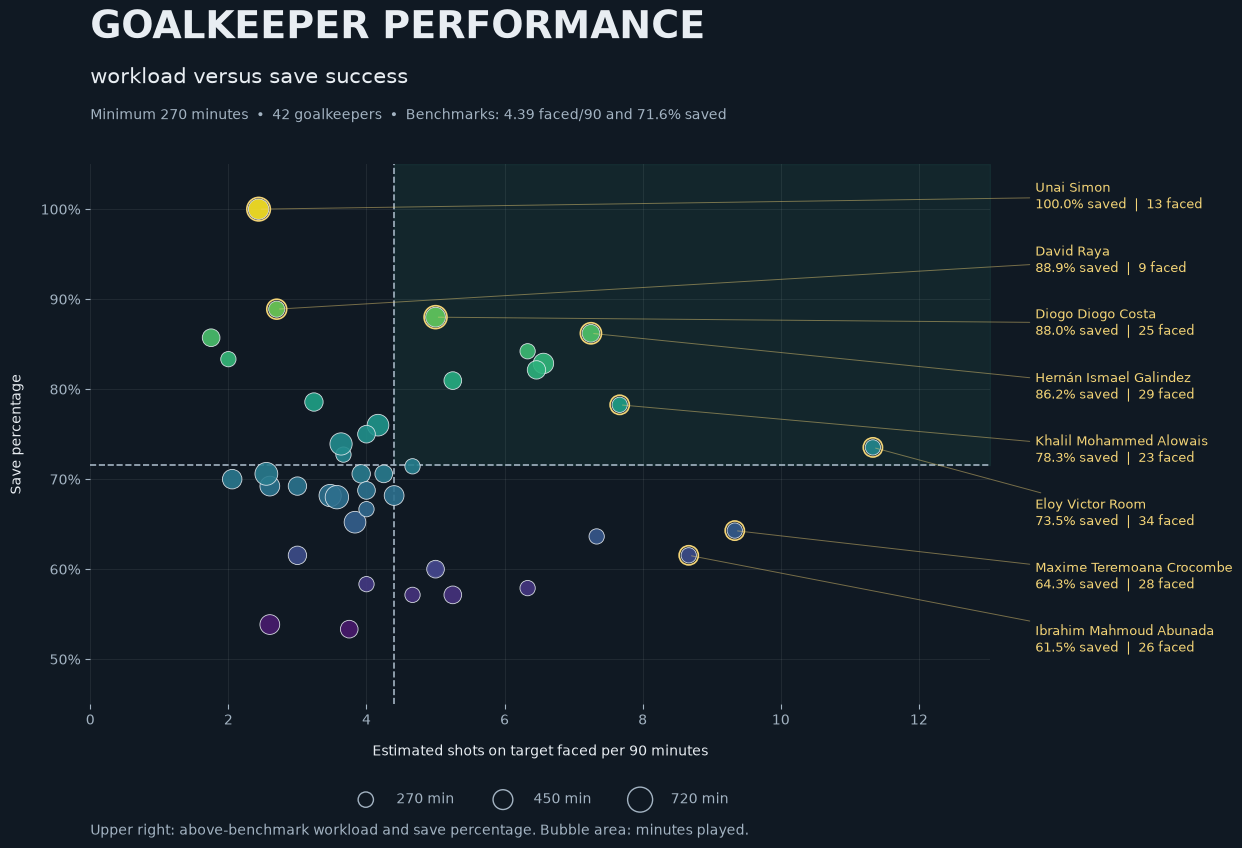

In [7]:
# Select goalkeepers with sufficient playing time
gk = players.loc[(players["position"] == "GK") & (players["minutes_played"] >= 270)
    ].dropna(subset=["saves", "goals_conceded", "minutes_played"]).copy()

# Estimate shots on target faced
gk["shots_faced"] = gk["saves"] + gk["goals_conceded"]
gk = gk[gk["shots_faced"] > 0].copy()

# Separate workload from save success
gk["shots_faced_per90"] = (gk["shots_faced"] / gk["minutes_played"] * 90)
gk["save_percentage"] = gk["saves"] / gk["shots_faced"] * 100

# Pooled benchmarks across eligible goalkeepers
workload_benchmark = (gk["shots_faced"].sum() / gk["minutes_played"].sum() * 90)
save_benchmark = gk["saves"].sum() / gk["shots_faced"].sum() * 100

# Label the four highest save percentages and four heaviest workloads
highlight = (gk.nlargest(4, "save_percentage").combine_first(gk.nlargest(4, "shots_faced_per90")).sort_values("save_percentage", ascending=False))

background = "#101923"
foreground = "#E8EDF2"
muted = "#A3B3C2"
accent = "#F3D477"

with plt.rc_context({"font.family": "DejaVu Sans", "text.color": foreground, "axes.labelcolor": foreground,
    "xtick.color": muted, "ytick.color": muted}):
    fig, ax = plt.subplots(figsize=(15, 9), facecolor=background)
    ax.set_facecolor(background)
    fig.subplots_adjust(left=0.09, right=0.69, top=0.80, bottom=0.20)

    xmax = gk["shots_faced_per90"].max() * 1.15
    ymin = max(0, np.floor(gk["save_percentage"].min() / 10) * 10 - 5)

    # Highlight the high-workload, high-save-percentage area
    ax.fill_between([workload_benchmark, xmax], save_benchmark, 105, color="#45D6B0", alpha=0.07)

    ax.axvline(workload_benchmark, color=muted, linestyle="--", linewidth=1.2)
    ax.axhline(save_benchmark, color=muted, linestyle="--", linewidth=1.2)

    # Bubble area represents playing time
    points = ax.scatter(gk["shots_faced_per90"], gk["save_percentage"], s=gk["minutes_played"] * 0.45, c=gk["save_percentage"],
        cmap="viridis", vmin=50, vmax=100, edgecolors=foreground, linewidths=0.6, alpha=0.9, zorder=3)

    ax.scatter(highlight["shots_faced_per90"], highlight["save_percentage"], s=highlight["minutes_played"] * 0.45 + 70, facecolors="none",
        edgecolors=accent, linewidths=1.2, zorder=4)

    # Place selected player labels outside the plotting area
    label_positions = np.linspace(0.94, 0.12, len(highlight))

    for (_, row), label_y in zip(highlight.iterrows(), label_positions):
        label = (
            f"{row['player_name']}\n"
            f"{row['save_percentage']:.1f}% saved"
            f"  |  {int(row['shots_faced'])} faced"
        )

        ax.annotate(label, xy=(row["shots_faced_per90"], row["save_percentage"]), xycoords="data", xytext=(1.05, label_y),
            textcoords="axes fraction", color=accent, fontsize=9, va="center", annotation_clip=False,
            arrowprops={"arrowstyle": "-", "color": accent, "linewidth": 0.7, "alpha": 0.45})

    ax.set_xlim(0, xmax)
    ax.set_ylim(ymin, 105)
    ax.set_yticks(np.arange(np.ceil(ymin / 10) * 10, 101, 10))
    ax.yaxis.set_major_formatter(PercentFormatter(100))

    ax.set_xlabel("Estimated shots on target faced per 90 minutes", labelpad=12)
    ax.set_ylabel("Save percentage", labelpad=12)
    ax.grid(color="white", alpha=0.07)
    ax.set_axisbelow(True)

    for spine in ax.spines.values():
        spine.set_visible(False)

    # Bubble-size legend
    size_handles = [
        ax.scatter([], [], s=minutes * 0.45, facecolors="none", edgecolors=muted, label=f"{minutes} min")
        for minutes in [270, 450, 720]
    ]

    ax.legend(handles=size_handles, loc="upper center", bbox_to_anchor=(0.5, -0.14), ncol=3, frameon=False, labelcolor=muted,
        handletextpad=1.2, columnspacing=2.5)

    fig.text(0.09, 0.94, "GOALKEEPER PERFORMANCE", fontsize=27, fontweight="bold")
    fig.text(0.09, 0.89, "workload versus save success", fontsize=15)
    fig.text(0.09, 0.85,
        f"Minimum 270 minutes  •  {len(gk)} goalkeepers  •  "
        f"Benchmarks: {workload_benchmark:.2f} faced/90 and "
        f"{save_benchmark:.1f}% saved", fontsize=10, color=muted
)
    fig.text(
        0.09, 0.055,
        "Upper right: above-benchmark workload and save percentage. "
        "Bubble area: minutes played.",
        fontsize=10, color=muted
    )

    plt.show()

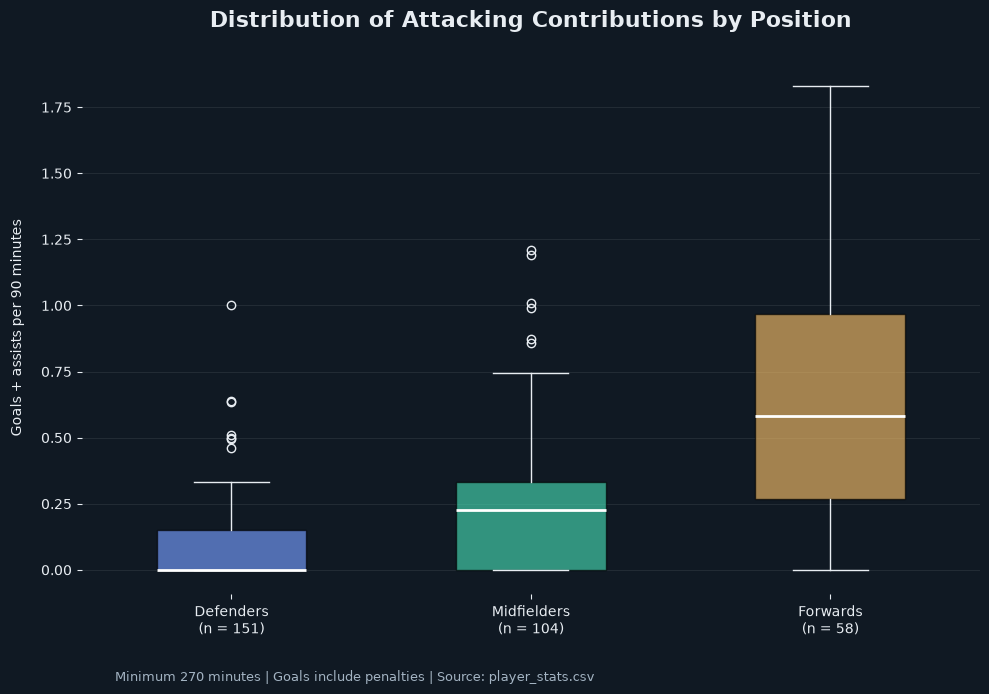

In [8]:
import matplotlib.pyplot as plt

# Select outfield players with at least 270 minutes
box_data = players.loc[
    players["position"].isin(["DEF", "MID", "FWD"]) &
    (players["minutes_played"] >= 270)
].dropna(subset=["goals", "assists", "minutes_played"]).copy()

box_data["contributions_per90"] = (
    (box_data["goals"] + box_data["assists"]) /
    box_data["minutes_played"] * 90
)

positions = ["DEF", "MID", "FWD"]
names = ["Defenders", "Midfielders", "Forwards"]
colors = ["#759DFF", "#45D6B0", "#F3BC68"]

groups = [
    box_data.loc[
        box_data["position"] == position, "contributions_per90"
    ]
    for position in positions
]

background = "#101923"
foreground = "#E8EDF2"

with plt.rc_context({
    "text.color": foreground,
    "axes.labelcolor": foreground,
    "xtick.color": foreground,
    "ytick.color": foreground
}):
    fig, ax = plt.subplots(figsize=(10, 7), facecolor=background)
    ax.set_facecolor(background)

    boxes = ax.boxplot(
        groups,
        patch_artist=True,
        widths=0.5,
        medianprops={"color": "white", "linewidth": 2},
        whiskerprops={"color": foreground},
        capprops={"color": foreground},
        flierprops={
            "marker": "o",
            "markerfacecolor": "none",
            "markeredgecolor": foreground,
            "markersize": 6
        }
    )

    for patch, color in zip(boxes["boxes"], colors):
        patch.set_facecolor(color)
        patch.set_alpha(0.65)

    ax.set_xticks([1, 2, 3])
    ax.set_xticklabels([
        f"{name}\n(n = {len(group)})"
        for name, group in zip(names, groups)
    ])

    ax.set_ylabel("Goals + assists per 90 minutes", labelpad=12)
    ax.set_title(
        "Distribution of Attacking Contributions by Position",
        fontsize=16, fontweight="bold", pad=25
    )

    ax.grid(axis="y", color="white", alpha=0.08)
    ax.set_axisbelow(True)

    for spine in ax.spines.values():
        spine.set_visible(False)

    fig.text(
        0.12, 0.02,
        "Minimum 270 minutes | Goals include penalties | Source: player_stats.csv",
        fontsize=9, color="#A3B3C2"
    )

    plt.tight_layout(rect=[0, 0.06, 1, 1])
    plt.show()

# Lecture 8.2

### Agenda: Will will talk about vibe coding, we'll have a break, and then he'll share some examples


### Questions

# Lab 8.2

**E.0** Complete the previous labs if you are behind.

**E.1** "Vibe coding" in practice, part 1. Take a dataset of your choice and use an LLM to do some kind of manipulation or analysis of that data. You should focus on trying something that you couldn't easily figure out on your own. Paste the resulting code and results here.

**E.2** "Vibe coding" in practice, part 2. Now take the same data set and make some kind of plot, again focusing on something that would be difficult to figure out on your own. Paste the resulting code and results here.

**E.3** Now let's think, does your use of AI in the examples above fit into Wiley's best practices framework? What are the dangers and oppertunities here? Use specific examples from the Wiley resources and relate them to your workflow above:

https://www.wiley.com/en-us/publishing/book/ai-guidelines

https://www.wiley.com/en-us/publishing/article/ai-guidelines

Specifically, when is it ethical to use AI for research, and when is it not? When is it in your best interest as a student to use AI, and when is it not? What are the enviornmental considerations of using AI? How might you use AI in your final project in line with ethical guidelines? You should be writng a few paragraphs at minimum with examples here. 


**E.4** Make notes for yourself on progamming tecniques and commands you learned in the this week, including examples, comments and explainitory text. You can do this here or in a separate notebook that you link to here. Basically, you are making a cheat sheet for yourself.